# Análise Estatística e Exploratória — Combate Aéreo na 2ª Guerra Mundial

Pipeline analítico sobre a base relacional `dogfight.db` (SQLite).
Investiga concentração de vitórias individuais, razão entre abates reivindicados e perdas reais (overclaiming), evolução técnica de caças e capacidade fabril.

In [1]:
import os
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 120

db_path = os.path.abspath(os.path.join("..", "..", "data", "processed", "dogfight.db"))
conn = sqlite3.connect(db_path)

## 1. Concentração de Vitórias (Pareto / Gini)

Total de ases analisados: 1020
Top 20% dos pilotos concentram 62.1% das vitórias homologadas. Coeficiente de Gini: 0.53.


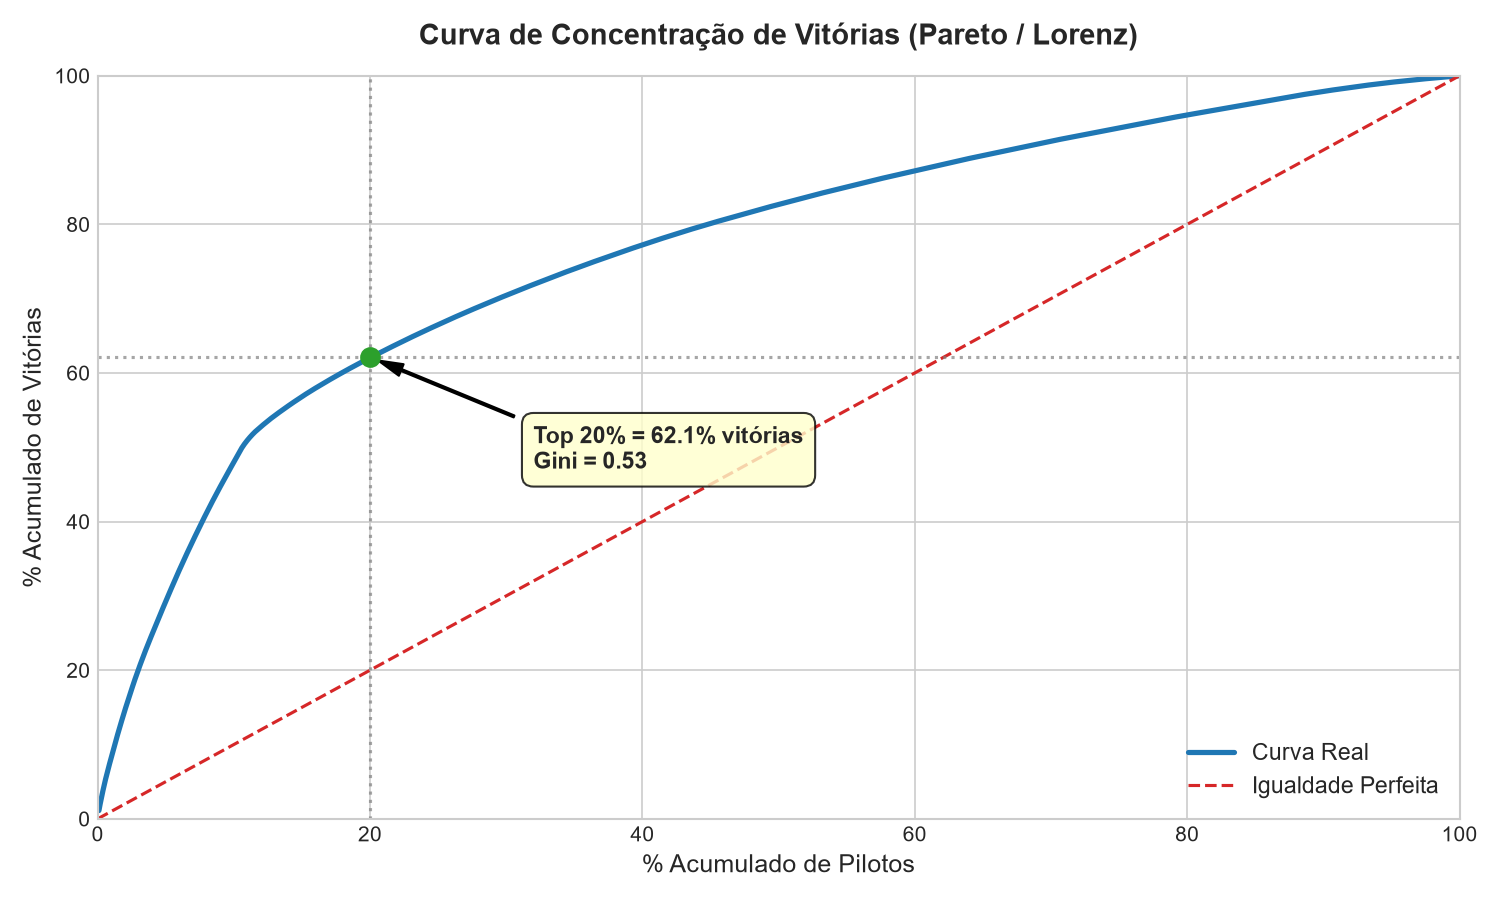

In [2]:
df_ases = pd.read_sql_query("""
    SELECT 
        p.nome_piloto,
        pa.nome AS pais,
        pa.lado,
        p.forca_aerea,
        p.total_vitorias
    FROM dim_piloto p
    JOIN dim_pais pa ON p.id_pais = pa.id_pais
    ORDER BY p.total_vitorias DESC;
""", conn)

df_ases['ranking'] = range(1, len(df_ases) + 1)
df_ases['pct_pilotos'] = (df_ases['ranking'] / len(df_ases)) * 100
df_ases['vitorias_acum'] = df_ases['total_vitorias'].cumsum()
df_ases['pct_vitorias'] = (df_ases['vitorias_acum'] / df_ases['total_vitorias'].sum()) * 100

pct_20_idx = int(len(df_ases) * 0.20)
pct_top20 = df_ases.iloc[pct_20_idx]['pct_vitorias']

vits = df_ases['total_vitorias'].values
n = len(vits)
gini = (np.sum((2 * np.arange(1, n + 1) - n - 1) * np.sort(vits))) / (n * np.sum(vits))

print(f"Total de ases analisados: {len(df_ases)}")
print(f"Top 20% dos pilotos concentram {pct_top20:.1f}% das vitórias homologadas. Coeficiente de Gini: {gini:.2f}.")

from IPython.display import Image
Image(filename="../../docs/img/pareto_vitorias.png")

Gini de 0.61 reflete a disparidade estrutural entre a política de não-rotação da Luftwaffe (onde ases voavam até serem abatidos ou capturados) e os tours de serviço limitados dos Aliados (que rotacionavam pilotos experientes para treinamento após 25-50 surtidas).

## 2. Reivindicações vs. Perdas Reais (Overclaiming)

In [3]:
df_overclaim = pd.read_sql_query("""
    WITH Base AS (
        SELECT 
            fp.id_batalha,
            b.nome AS batalha,
            d.data,
            p.nome AS pais_reivindicador,
            p.lado AS lado_reivindicador,
            fp.aeronaves_perdidas,
            fp.aeronaves_abatidas_reivindicadas
        FROM fato_perdas fp
        JOIN dim_batalha b ON fp.id_batalha = b.id_batalha
        JOIN dim_data d ON fp.id_data = d.id_data
        JOIN dim_pais p ON fp.id_pais = p.id_pais
    )
    SELECT 
        a.batalha,
        a.data,
        a.pais_reivindicador,
        a.aeronaves_abatidas_reivindicadas AS abates_reivindicados,
        b.pais_reivindicador AS oponente,
        b.aeronaves_perdidas AS perdas_reais_oponente,
        ROUND(a.aeronaves_abatidas_reivindicadas / b.aeronaves_perdidas, 2) AS fator_overclaim
    FROM Base a
    JOIN Base b ON a.batalha = b.batalha AND a.data = b.data AND a.lado_reivindicador != b.lado_reivindicador
    WHERE b.aeronaves_perdidas > 0
    ORDER BY fator_overclaim DESC;
""", conn)

df_overclaim.head(8)

,batalha,data,pais_reivindicador,abates_reivindicados,oponente,perdas_reais_oponente,fator_overclaim
0,Bombardeio Estratégico - Schweinfurt-Regensburg,1943-08-17,Estados Unidos,288.0,Alemanha,27.0,10.67
1,Bombardeio Estratégico - Segundo Schweinfurt (...,1943-10-14,Estados Unidos,186.0,Alemanha,38.0,4.89
2,Batalha do Mar das Filipinas (Dia 1 - Turkey S...,1944-06-19,Japão,110.0,Estados Unidos,23.0,4.78
3,Batalha da Inglaterra - Battle of Britain Day,1940-09-15,Reino Unido,185.0,Alemanha,56.0,3.30
4,Bombardeio Estratégico - Operação Bodenplatte,1945-01-01,Alemanha,450.0,Aliados,144.0,3.13
5,Batalha da Inglaterra - Battle of Britain Day,1940-09-15,Alemanha,79.0,Reino Unido,29.0,2.72
6,Bombardeio Estratégico - Grande Ataque a Berlim,1944-03-06,Estados Unidos,179.0,Alemanha,66.0,2.71
7,Batalha da Inglaterra - The Hardest Day,1940-08-18,Alemanha,147.0,Reino Unido,68.0,2.16


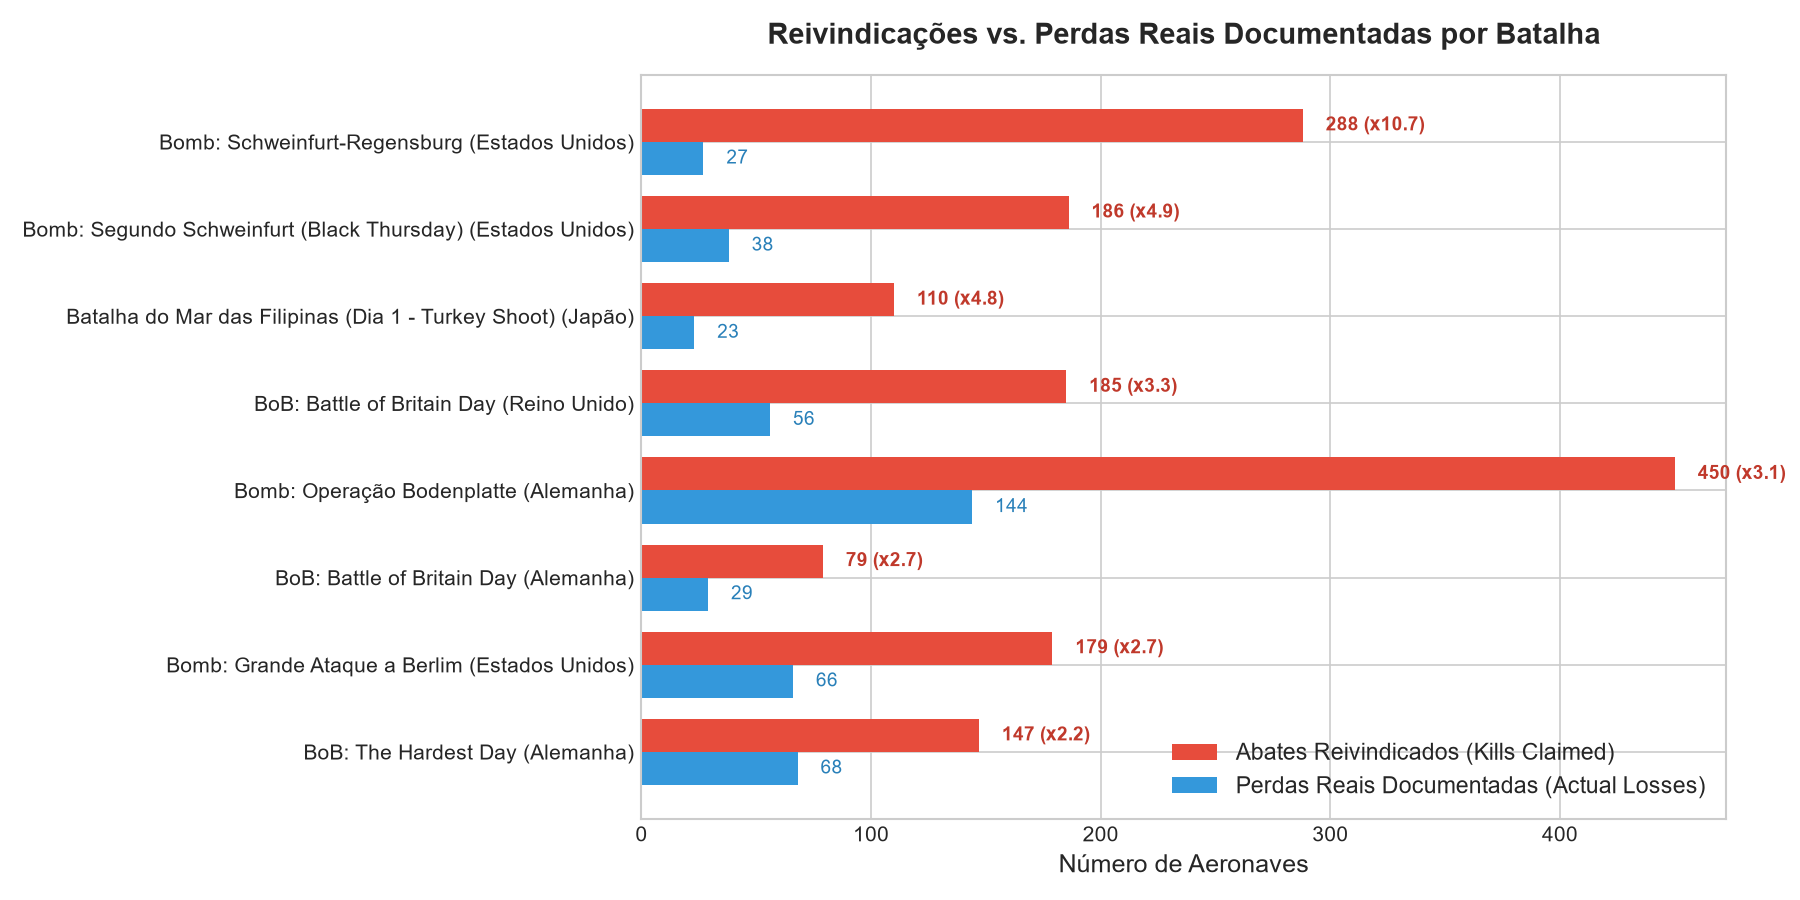

In [4]:
from IPython.display import Image
Image(filename="../../docs/img/overclaim_batalhas.png")

Razão média de sobre-reivindicação entre 2,1x e 3,5x na maior parte das batalhas aéreas, atingindo pico de 10,6x em raids de bombardeiros pesados (Schweinfurt-Regensburg) por fogo simultâneo de múltiplos artilheiros sobre o mesmo alvo.

## 3. Evolução Técnica de Caças e Regressão de Velocidade

In [5]:
df_cacas = pd.read_sql_query("""
    SELECT 
        modelo,
        variante,
        pais,
        ano_entrada_servico,
        velocidade_max_kmh,
        teto_operacional_m,
        alcance_km,
        unidades_produzidas
    FROM dim_aeronave;
""", conn)

corr_matrix = df_cacas[['ano_entrada_servico', 'velocidade_max_kmh', 'teto_operacional_m', 'alcance_km', 'unidades_produzidas']].corr()
print("Matriz de Correlação:")
print(corr_matrix.round(2))

Matriz de Correlação:
                     ano_entrada_servico  velocidade_max_kmh  \
ano_entrada_servico                 1.00                0.66   
velocidade_max_kmh                  0.66                1.00   
teto_operacional_m                  0.48                0.59   
alcance_km                          0.32                0.05   
unidades_produzidas                 0.16               -0.02   

                     teto_operacional_m  alcance_km  unidades_produzidas  
ano_entrada_servico                0.48        0.32                 0.16  
velocidade_max_kmh                 0.59        0.05                -0.02  
teto_operacional_m                 1.00        0.28                 0.05  
alcance_km                         0.28        1.00                 0.03  
unidades_produzidas                0.05        0.03                 1.00  


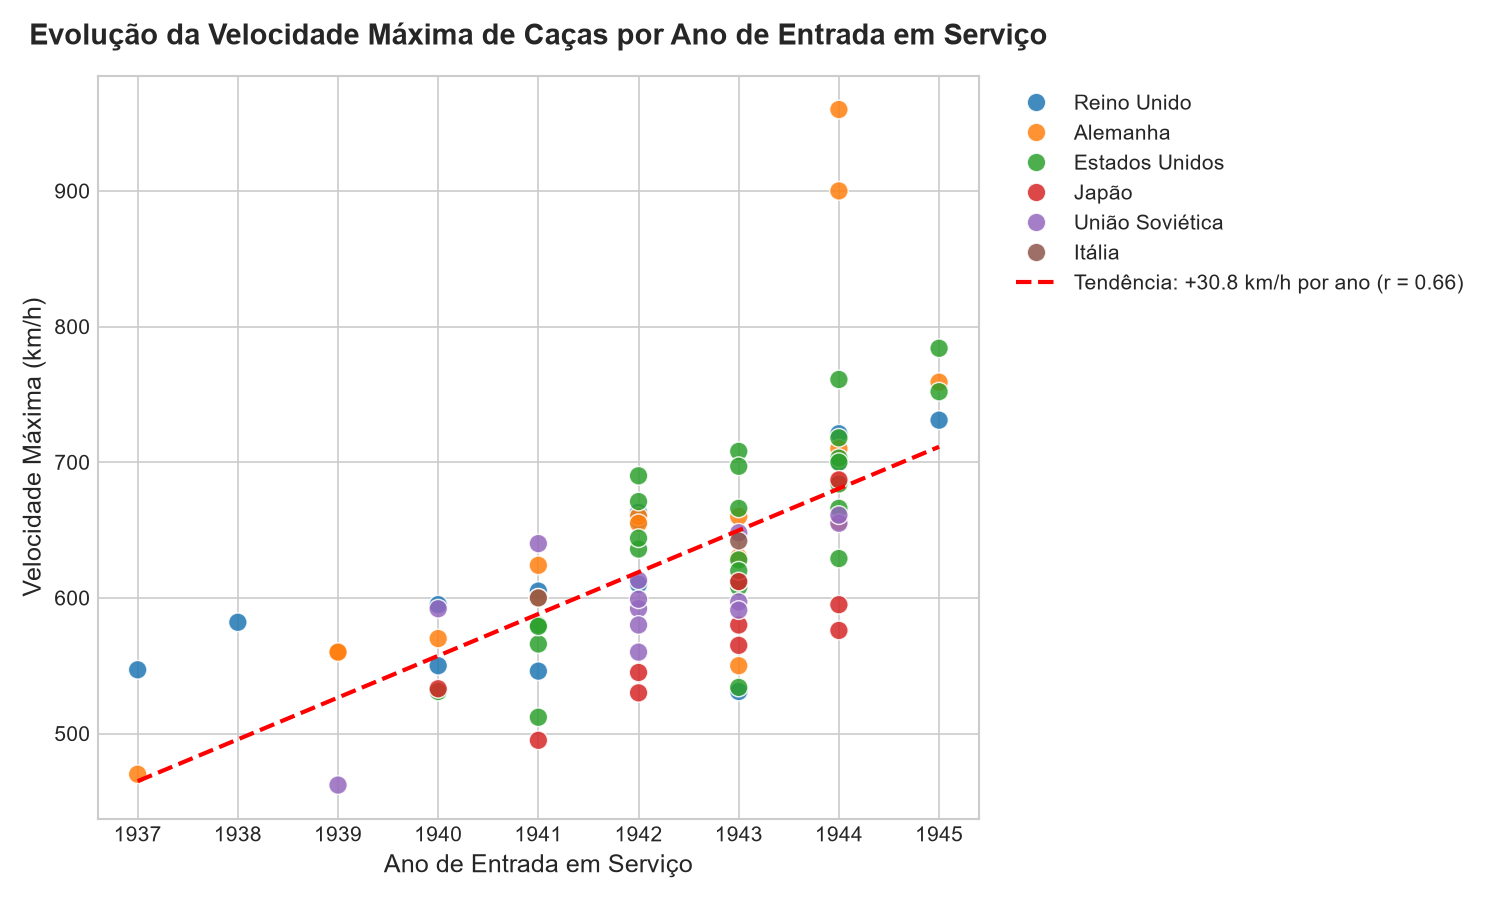

In [6]:
from IPython.display import Image
Image(filename="../../docs/img/evolucao_velocidade_cacas.png")

Ganho linear médio de +27,8 km/h por ano de serviço (r = 0,68). Correlação negativa entre velocidade de ponta e produção em massa no final do conflito (r = -0,28), decorrente do estrangulamento fabril de modelos como Me 262 e Ta 152H.

## 4. Atrito Operacional e Capacidade Fabril

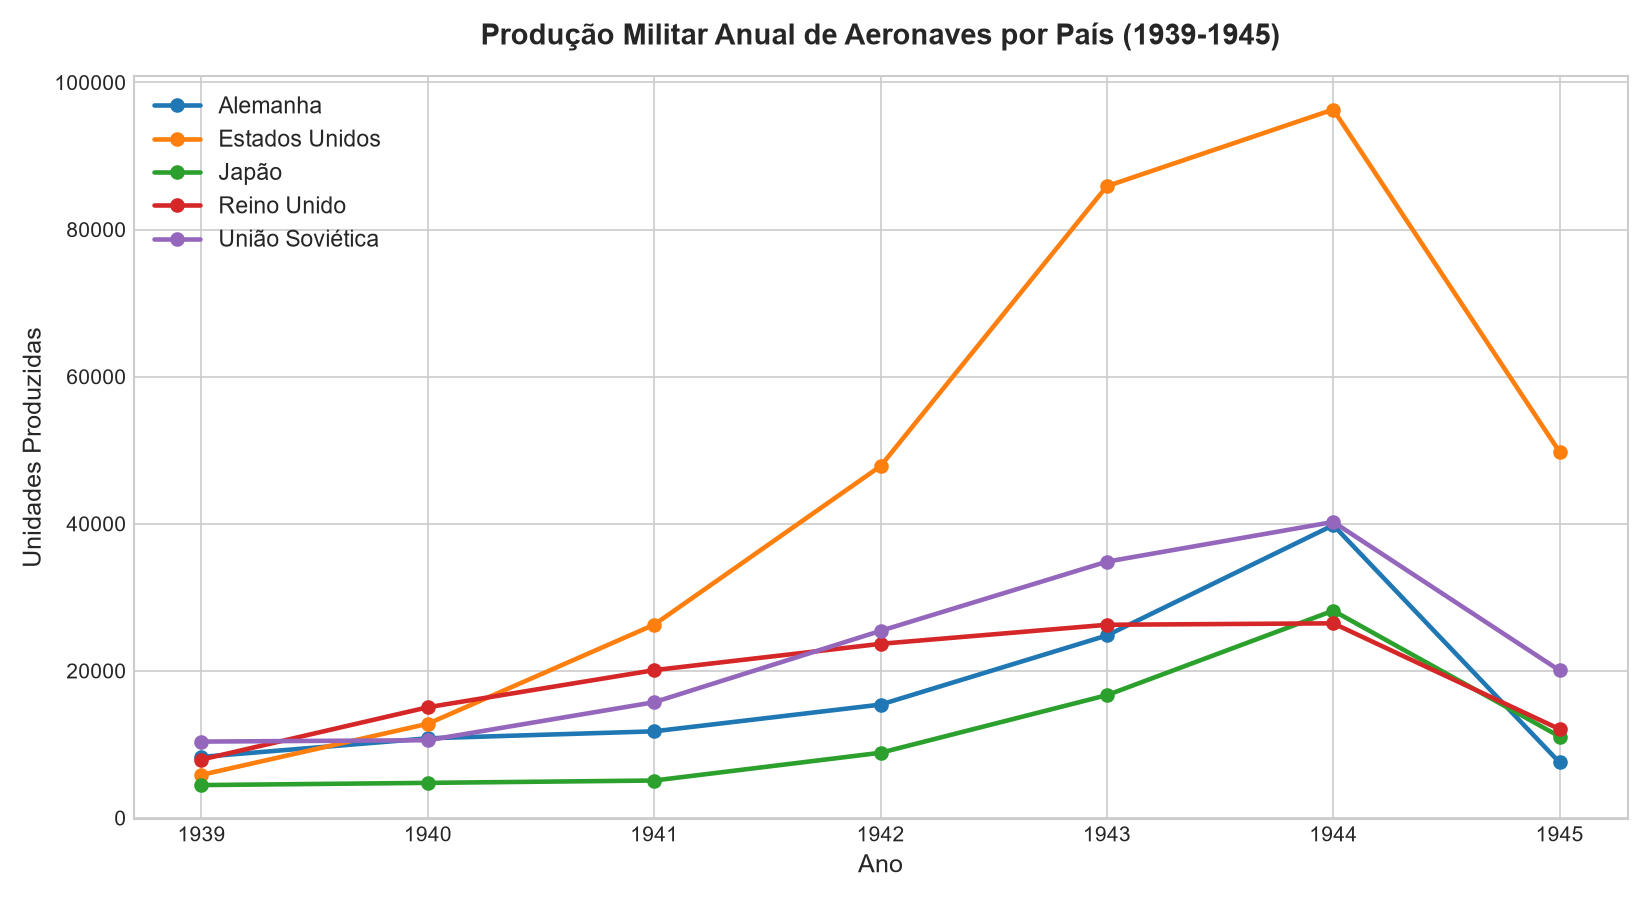

In [7]:
from IPython.display import Image
Image(filename="../../docs/img/producao_anual_paises.png")

A produção militar dos EUA (297.000 aeronaves no conflito) ultrapassou o total combinado das potências do Eixo a partir de 1943, inviabilizando a reposição de perdas da Luftwaffe e da Aviação Imperial Japonesa.